**Import Libraries**


In [122]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

**Load Dataset**

In [123]:
df = pd.read_csv("SuperStore_Sales_Dataset.csv", encoding='latin1')

**Data Understanding**

In [124]:
df.head()

,ï»¿Row ID+O6G3A1:R6,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Profit,Returns,Payment Mode,ind1,ind2
0,4918,CA-2019-160304,01-01-2019,07-01-2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",73.94,1,28.2668,NaN,Online,NaN,NaN
1,4919,CA-2019-160304,02-01-2019,07-01-2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Furniture,Bookcases,"Bush Westfield Collection Bookcases, Medium Ch...",173.94,3,38.2668,NaN,Online,NaN,NaN
2,4920,CA-2019-160304,02-01-2019,07-01-2019,Standard Class,BM-11575,Brendan Murry,Corporate,United States,Gaithersburg,...,Technology,Phones,GE 30522EE2,231.98,2,67.2742,NaN,Cards,NaN,NaN
3,3074,CA-2019-125206,03-01-2019,05-01-2019,First Class,LR-16915,Lena Radford,Consumer,United States,Los Angeles,...,Office Supplies,Storage,Recycled Steel Personal File for Hanging File ...,114.46,2,28.6150,NaN,Online,NaN,NaN
4,8604,US-2019-116365,03-01-2019,08-01-2019,Standard Class,CA-12310,Christine Abelman,Corporate,United States,San Antonio,...,Technology,Accessories,ImationÂ Clip USBÂ flash driveÂ - 8 GB,30.08,2,-5.2640,NaN,Online,NaN,NaN


In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5901 entries, 0 to 5900
Data columns (total 23 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ï»¿Row ID+O6G3A1:R6  5901 non-null   int64  
 1   Order ID             5901 non-null   object 
 2   Order Date           5901 non-null   object 
 3   Ship Date            5901 non-null   object 
 4   Ship Mode            5901 non-null   object 
 5   Customer ID          5901 non-null   object 
 6   Customer Name        5901 non-null   object 
 7   Segment              5901 non-null   object 
 8   Country              5901 non-null   object 
 9   City                 5901 non-null   object 
 10  State                5901 non-null   object 
 11  Region               5901 non-null   object 
 12  Product ID           5901 non-null   object 
 13  Category             5901 non-null   object 
 14  Sub-Category         5901 non-null   object 
 15  Product Name         5901 non-null   o

In [126]:
df.describe()

,ï»¿Row ID+O6G3A1:R6,Sales,Quantity,Profit,Returns,ind1,ind2
count,5901.000000,5901.000000,5901.000000,5901.000000,287.0,0.0,0.0
mean,5022.422471,265.345589,3.781901,29.700408,1.0,NaN,NaN
std,2877.977184,474.260645,2.212917,259.589138,0.0,NaN,NaN
min,1.000000,0.836000,1.000000,-6599.978000,1.0,NaN,NaN
25%,2486.000000,71.976000,2.000000,1.795500,1.0,NaN,NaN
50%,5091.000000,128.648000,3.000000,8.502500,1.0,NaN,NaN
75%,7456.000000,265.170000,5.000000,28.615000,1.0,NaN,NaN
max,9994.000000,9099.930000,14.000000,8399.976000,1.0,NaN,NaN


In [127]:
df.isnull().sum()

,0
ï»¿Row ID+O6G3A1:R6,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Customer Name,0
Segment,0
Country,0
City,0


**Data Cleaning**

*Remove useless columns*

In [128]:
df.drop(columns=[
    'ï»¿Row ID+O6G3A1:R6',
    'ind1',
    'ind2'
], inplace=True)

*Convert dates*

In [129]:
df["Order Date"] = pd.to_datetime(df["Order Date"],dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"],dayfirst=True)

*Handle Returns*

In [130]:
df["Returned"] = df["Returns"].notna().astype(int)

df.drop("Returns", axis=1, inplace=True)

**Feature Engineering**

*Create High Sales Target*

In [131]:
df["High Sales"] = np.where(df["Sales"] > df["Sales"].median(),1,0)

*Create Year and Month*

In [132]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month

*Shipping Days*

In [133]:
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

*Sales Per Item*

In [134]:
df["Sales Per Item"] = (df["Sales"] / df["Quantity"])

*Select Features*

In [135]:
data = df[[
    "Quantity",
    "Category",
    "Region",
    "Returned",
    "Year",
    "Month",
    "Shipping Days",
    "Sales Per Item",
    "High Sales"
]]

*Encoding*

In [136]:
data = pd.get_dummies(data,columns=["Category","Region"],drop_first=True)

**Split Features & Target**

In [137]:
X = data.drop("High Sales", axis=1)
y = data["High Sales"]

*Train Test Split*

In [138]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

*Scaling*

In [139]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Logistic Regression**

In [140]:
log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

*Logistic Regression Prediction*

In [141]:
log_pred = log_model.predict(X_test_scaled)

*Logistic Regression Accuracy*

In [142]:
log_accuracy = accuracy_score(y_test,log_pred)
print("Logistic Regression Accuracy:")
print(log_accuracy)

Logistic Regression Accuracy:
0.842506350550381


**Classification Report**

In [143]:
print(classification_report(y_test,log_pred))

              precision    recall  f1-score   support

           0       0.81      0.89      0.85       591
           1       0.88      0.80      0.84       590

    accuracy                           0.84      1181
   macro avg       0.85      0.84      0.84      1181
weighted avg       0.85      0.84      0.84      1181



**Confusion Matrix**

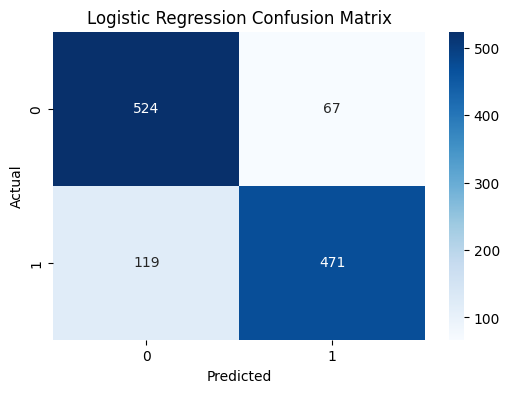

In [144]:
cm = confusion_matrix(y_test,log_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

**ROC Curve**

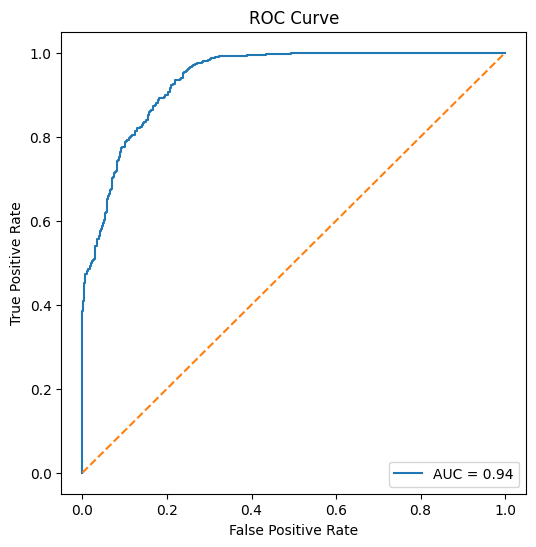

In [145]:
y_prob = log_model.predict_proba(X_test_scaled)[:,1]
fpr, tpr, thresholds = roc_curve(y_test,y_prob)
roc_auc = auc(fpr, tpr)
plt.figure(figsize=(6,6))
plt.plot(fpr,tpr,label=f'AUC = {roc_auc:.2f}')
plt.plot([0,1],[0,1],linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

**Compare Train vs Test Accuracy**

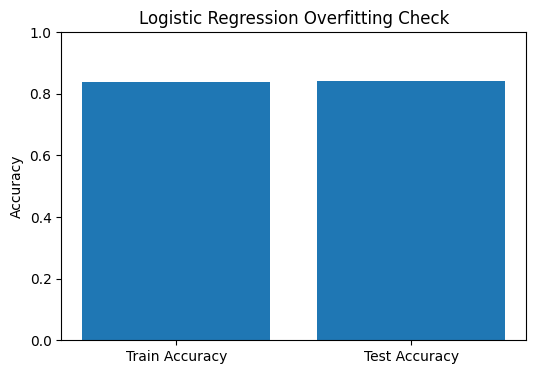

In [151]:
train_accuracy = log_model.score(X_train_scaled, y_train)
test_accuracy = log_model.score(X_test_scaled,y_test)
scores = [train_accuracy, test_accuracy]
labels = [
    "Train Accuracy",
    "Test Accuracy"
]
plt.figure(figsize=(6,4))
plt.bar(labels, scores)
plt.ylim(0,1)
plt.title(
    "Logistic Regression Overfitting Check"
)
plt.ylabel("Accuracy")
plt.show()

In [147]:
# df.to_csv("cleaned_superstore.csv",index=False)